# Data Preparation

In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

In [38]:
# Load dataset
df = pd.read_excel("/content/compressed_features.xlsx")
print("Dataset shape:", df.shape)
print("First 5 rows:\n", df.head())

Dataset shape: (100000, 7)
First 5 rows:
    Lifestyle  Interests  Communication  Responsibility  SocialEngagement  \
0      3.625      3.375          3.125             2.6          2.444444   
1      4.125      3.125          2.375             3.2          2.222222   
2      3.500      2.500          2.750             2.6          2.666667   
3      3.000      3.125          2.875             2.6          2.777778   
4      4.000      3.500          3.000             3.6          2.444444   

   EmotionalStability  Openness  
0            2.833333  2.833333  
1            2.166667  3.166667  
2            2.333333  3.500000  
3            2.833333  2.666667  
4            2.333333  3.000000  


In [ ]:
# Handling missing values
print(df.isna().sum())

Lifestyle             3
Interests             3
Communication         3
Responsibility        3
SocialEngagement      3
EmotionalStability    3
Openness              3
dtype: int64


In [39]:
df = df.dropna()
print("dataset shape:", df.shape)

dataset shape: (99997, 7)


In [ ]:
# Extract features
X = df.values.astype(float)
print("X shape:", X.shape)

X shape: (99997, 7)


In [ ]:
# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled X mean:", X_scaled.mean(axis=0))
print("Scaled X std:", X_scaled.std(axis=0))

Scaled X mean: [-2.45570937e-16 -1.06868834e-16 -3.14353537e-16  1.05390860e-15
 -2.52392352e-16 -1.00274799e-15 -1.22558088e-15]
Scaled X std: [1. 1. 1. 1. 1. 1. 1.]


In [ ]:
# convert to PyTorch tensor
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)

In [ ]:
# create dataset and dataloader
dataset = TensorDataset(X_tensor)
batch_size = 256
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

print("Number of batches:", len(dataloader))

Number of batches: 391


# Autoencoder

In [8]:
class Autoencoder(nn.Module):
  def __init__(self):
    super(Autoencoder, self).__init__()

    latent_dim = 5

    # Encoder
    self.encoder = nn.Sequential(
        nn.Linear(7, 32),
        nn.BatchNorm1d(32),
        nn.ReLU(),
        nn.Linear(32, 16),
        nn.BatchNorm1d(16),
        nn.ReLU(),
        nn.Linear(16, latent_dim), # latent layer
    )

    # Decoder
    self.decoder = nn.Sequential(
        nn.Linear(latent_dim, 16),
        nn.BatchNorm1d(16),
        nn.ReLU(),
        nn.Linear(16, 32),
        nn.BatchNorm1d(32),
        nn.ReLU(),
        nn.Linear(32, 7) # reconstruct input
    )

  def forward(self, x):
    z = self.encoder(x) # compress
    x_recon = self.decoder(z) # reconstruct
    return x_recon

In [ ]:
import random
import torch.nn as nn
from torch.utils.data import random_split

In [ ]:
# reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [11]:
print(device)

cuda


We train on 95% of the data and test reconstruction on the other 5%.
If the **validation loss** keeps going down, it means the model is learning general structure.
If it starts **rising while training loss keeps dropping**, it means we're **overfitting**: memorizing instead of learning patterns.

In [ ]:
# small validation split (e.g. 5% val) to check for overfitting
val_frac = 0.05
n = len(X_tensor)
n_val = int(n * val_frac)
n_train = n - n_val
train_ds, val_ds = random_split(TensorDataset(X_tensor), [n_train, n_val])

In [ ]:
batch_size = 256

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

# validation is not shuffled since it's only used for evaluation.
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

In [ ]:
model = Autoencoder().to(device)

# lower learning rate for stability
lr = 1e-4
optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)

This schedular monitors validation loss; If the validation loss stop imporving for several epochs (`patience=8`), it automatically reduces the learning rate by half (`factor=0.5`)

In [ ]:
# scheduler (ReduceLROnPlateau reacts to val loss)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min',
                                                       factor=0.5, patience=8)

criterion = nn.MSELoss()

### Training loop

In [ ]:
num_epochs = 100
print_every = 10
train_losses = []
val_losses = []

# helper to compute average loss on a loader
# It will tell us how well the model is reconstructing unseen data after each epoch.
def eval_loss(loader):
    model.eval()
    total = 0.0
    count = 0
    with torch.no_grad(): # disabling gradient computation
        for batch in loader:
            x = batch[0].to(device)
            x_recon = model(x)
            loss = criterion(x_recon, x)
            total += loss.item() * x.size(0)
            count += x.size(0)
    return total / count

In [ ]:
# train loop with gradient norm monitoring
for epoch in range(num_epochs):
    model.train()
    total_loss = 0.0
    n_samples = 0
    for batch in train_loader:
        x = batch[0].to(device)
        x_recon = model(x)
        loss = criterion(x_recon, x)

        optimizer.zero_grad()
        loss.backward()

        optimizer.step()
        total_loss += loss.item() * x.size(0)
        n_samples += x.size(0)

    avg_train = total_loss / n_samples # mean training loss across all batches
    train_losses.append(avg_train)

    # validation loss
    avg_val = eval_loss(val_loader)
    val_losses.append(avg_val)

    # scheduler step on val loss
    scheduler.step(avg_val)

    if (epoch + 1) % print_every == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{num_epochs} | train_loss={avg_train:.6f} | val_loss={avg_val:.6f} | lr={optimizer.param_groups[0]['lr']:.2e}")

Epoch 1/100 | train_loss=0.776008 | val_loss=0.546879 | lr=1.00e-04
Epoch 10/100 | train_loss=0.177625 | val_loss=0.169993 | lr=1.00e-04
Epoch 20/100 | train_loss=0.155059 | val_loss=0.151513 | lr=1.00e-04
Epoch 30/100 | train_loss=0.144611 | val_loss=0.137026 | lr=1.00e-04
Epoch 40/100 | train_loss=0.137236 | val_loss=0.130279 | lr=1.00e-04
Epoch 50/100 | train_loss=0.131001 | val_loss=0.124722 | lr=1.00e-04
Epoch 60/100 | train_loss=0.126155 | val_loss=0.118907 | lr=1.00e-04
Epoch 70/100 | train_loss=0.121328 | val_loss=0.117090 | lr=1.00e-04
Epoch 80/100 | train_loss=0.117154 | val_loss=0.110579 | lr=1.00e-04
Epoch 90/100 | train_loss=0.114102 | val_loss=0.106862 | lr=1.00e-04
Epoch 100/100 | train_loss=0.111059 | val_loss=0.106804 | lr=1.00e-04


In [ ]:
# after training: gradient norms (last batch)
model.eval()
grad_norms = []
for p in model.parameters():
    if p.grad is not None:
        grad_norms.append(p.grad.detach().cpu().norm().item())
if grad_norms:
    print("Gradient norm stats (min, mean, max):", np.min(grad_norms), np.mean(grad_norms), np.max(grad_norms))
else:
    print("No gradients available (maybe evaluated after optimizer.step).")


Gradient norm stats (min, mean, max): 1.0407295469860856e-08 0.2922393218852636 1.2706459760665894


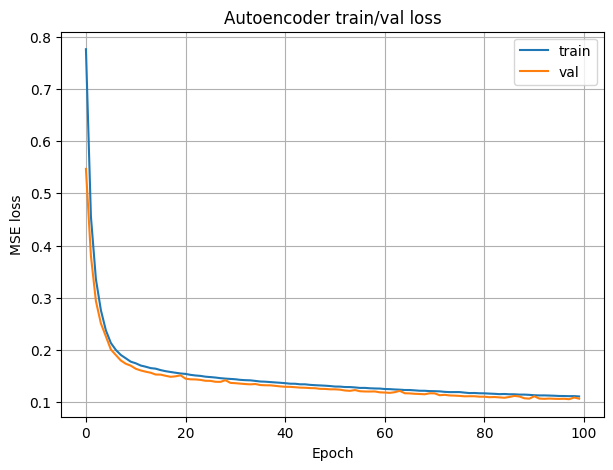

In [ ]:
# plot and save
plt.figure(figsize=(7,5))
plt.plot(train_losses, label='train')
plt.plot(val_losses, label='val')
plt.xlabel('Epoch')
plt.ylabel('MSE loss')
plt.yscale('linear')
plt.legend()
plt.grid(True)
plt.title('Autoencoder train/val loss')
plt.savefig('ae_loss_curve.png', dpi=150)
plt.show()


- **Early epochs:** The loss drops steeply in the first 10 epochs which is normal because the model is rapidly learning the basic structure of the data.
- **Middle Phase (10-30 epochs):** After the sharp drop, the losses continue decreasing but more slowly.
- **Later phase (30-100 epochs):** The curves flatten out smoothly, meaning the model has nearly converged. It's not learning much new, and the loss stabilized.

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


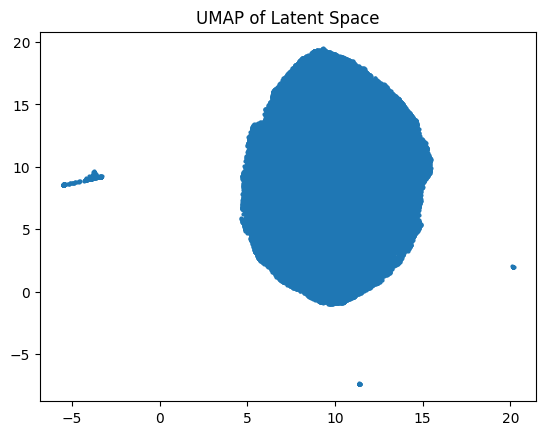

In [ ]:
# UMAP
import umap.umap_ as umap

model.eval()
with torch.no_grad():
    Z = model.encoder(X_tensor.to(device)).cpu().numpy()

umap_model = umap.UMAP(n_components=2, random_state=42)
Z_umap = umap_model.fit_transform(Z)

plt.scatter(Z_umap[:, 0], Z_umap[:, 1], s=4)
plt.title("UMAP of Latent Space")
plt.savefig('UMAP.png', dpi=150)
plt.show()

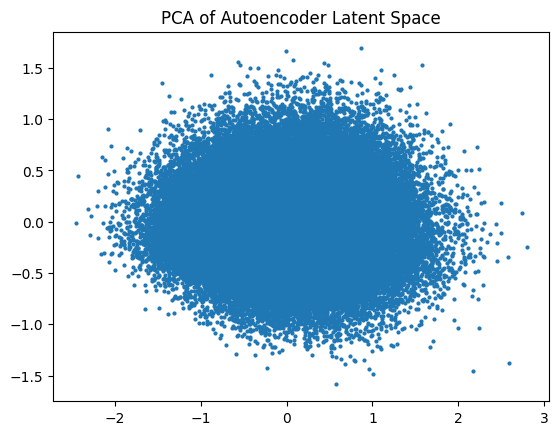

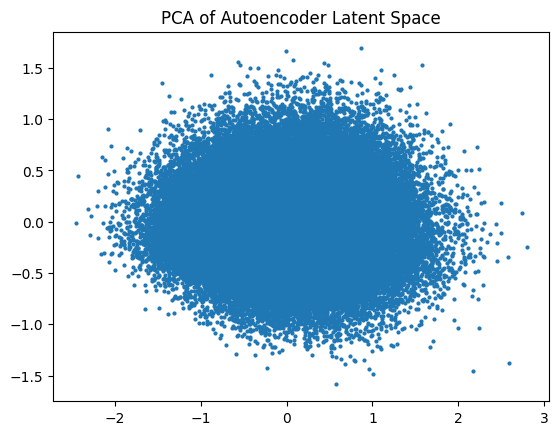

In [ ]:
# PCA
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
Z_pca = pca.fit_transform(Z)

plt.scatter(Z_pca[:, 0], Z_pca[:, 1], s=4)
plt.title("PCA of Autoencoder Latent Space")
plt.savefig('PCA.png', dpi=150)
plt.show()

In [ ]:
# saving the model weights
torch.save(model.state_dict(), "autoencoder_weights.pth")

## for reloading:
# model.load_state_dict(torch.load("autoencoder_weights.pth"))
# model.to(device)
# model.eval()

# Extract Embeddings (z)

In [ ]:
model.to(device)
model.eval()

# building a dataloader for your entire dataset (no labels, no shuffle)
full_dataset = TensorDataset(torch.tensor(X_scaled, dtype=torch.float32))
full_loader = DataLoader(full_dataset, batch_size=1024, shuffle=False)

embeddings = []
with torch.no_grad(): # disabling gradient calculation
  for batch in full_loader:
    x = batch[0].to(device)
    z = model.encoder(x) # pass through encoder only
    embeddings.append(z.cpu().numpy())

# combine all batches into a single array
Z = np.vstack(embeddings) # shape: (num_samples, latent_dim)

print("Z shape:", Z.shape)
print("Z mean per dim:", np.mean(Z, axis=0))
print("Z std per dim:", np.std(Z, axis=0))

np.save("embeddings.npy", Z)

Z shape: (99997, 5)
Z mean per dim: [-0.04916058  0.07763644 -0.0351117   0.07712284 -0.04121674]
Z std per dim: [0.3871051  0.31047386 0.3411996  0.4619076  0.3462194 ]


# KMeans Initialization

## Let's first find the best k
This was done during the implementation of other models in other notebook files and we will use that knowledge here as well. But here I'm trying to use more metrics instead of just the best silhouette score.

In [32]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from collections import Counter

In [ ]:
rng = np.random.RandomState(42)

ks = list(range(2, 13)) # trying k=2...12
inertias = []
sil_scores = []
ch_scores = []
db_scores = []
cluster_counts = {}

In [ ]:
# choosing sample size for sil to save time: up to 10000
sil_sample_size = min(10000, Z.shape[0])
sil_idx = rng.choice(Z.shape[0], size=sil_sample_size, replace=False)
Z_sil = Z[sil_idx]

In [ ]:
for k in ks:
  print(f"\nFitting k={k} ...")
  kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
  labels = kmeans.fit_predict(Z)

  # recording clustering metrics
  inertias.append(kmeans.inertia_)
  ch_scores.append(calinski_harabasz_score(Z, labels))
  db_scores.append(davies_bouldin_score(Z, labels))

  # evaluating sil score on a sample
  sample_labels = kmeans.predict(Z_sil)
  sil = silhouette_score(Z_sil, sample_labels)
  sil_scores.append(sil)

  # cluster counts
  cluster_counts[k] = dict(Counter(labels))

  # printing results
  print(f"  inertia: {kmeans.inertia_:.2f}, silhouette(sample):{sil:.4f}, CH: {ch_scores[-1]:.2f}, DB: {db_scores[-1]:.4f}")
  sizes = sorted(cluster_counts[k].items(), key=lambda x: x[1], reverse=True)
  print(" cluster sizes (k, size) top 5:", sizes[:5])



Fitting k=2 ...
  inertia: 601043.12, silhouette(sample):0.3136, CH: 54861.21, DB: 1.1821
 cluster sizes (k, size) top 5: [(np.int32(0), 57124), (np.int32(1), 42873)]

Fitting k=3 ...
  inertia: 492805.03, silhouette(sample):0.3150, CH: 44435.58, DB: 0.9013
 cluster sizes (k, size) top 5: [(np.int32(0), 53675), (np.int32(1), 45769), (np.int32(2), 553)]

Fitting k=4 ...
  inertia: 407303.00, silhouette(sample):0.2319, CH: 42839.89, DB: 1.1253
 cluster sizes (k, size) top 5: [(np.int32(0), 46067), (np.int32(1), 31683), (np.int32(3), 21702), (np.int32(2), 545)]

Fitting k=5 ...
  inertia: 369438.72, silhouette(sample):0.2082, CH: 37984.31, DB: 1.2962
 cluster sizes (k, size) top 5: [(np.int32(0), 30155), (np.int32(2), 28065), (np.int32(4), 21094), (np.int32(3), 20140), (np.int32(1), 543)]

Fitting k=6 ...
  inertia: 338475.66, silhouette(sample):0.1803, CH: 34996.46, DB: 1.3431
 cluster sizes (k, size) top 5: [(np.int32(3), 26920), (np.int32(5), 24531), (np.int32(2), 18647), (np.int32(0)

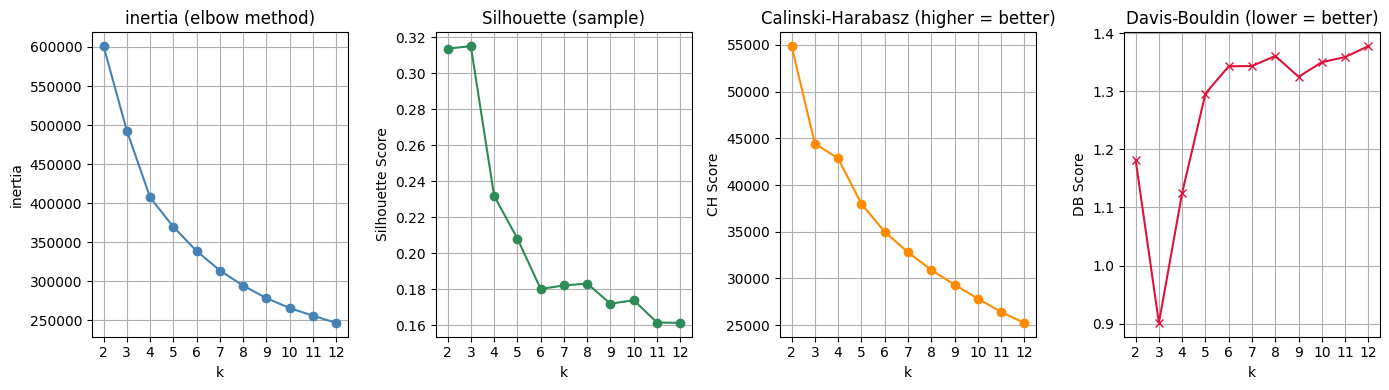

In [ ]:
# plotting the results
plt.figure(figsize=(14, 4))

x_ticks = ks

# plotting inertia (elbow method)
plt.subplot(1, 4, 1)
plt.plot(ks, inertias, marker='o', color='steelblue')
plt.xlabel('k')
plt.ylabel('inertia')
plt.title('inertia (elbow method)')
plt.grid(True)
plt.xticks(x_ticks)

# plotting silhouette score
plt.subplot(1, 4, 2)
plt.plot(ks, sil_scores, marker='o', color='seagreen')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.title('Silhouette (sample)')
plt.grid(True)
plt.xticks(x_ticks)

# plotting CH score
plt.subplot(1, 4, 3)
plt.plot(ks, ch_scores, marker='o', color='darkorange')
plt.xlabel('k')
plt.ylabel('CH Score')
plt.title('Calinski-Harabasz (higher = better)')
plt.grid(True)
plt.xticks(x_ticks)

# plotting DB score
plt.subplot(1, 4, 4)
plt.plot(ks, db_scores, marker = 'x', color='crimson')
plt.xlabel('k')
plt.ylabel('DB Score')
plt.title('Davis-Bouldin (lower = better)')
plt.grid(True)
plt.xticks(x_ticks)

plt.tight_layout()
plt.savefig('k_selection_metrics.png', dpi=150)
plt.show()

### Interpretation
- The silhouette and CH score suggest 2-3 clusters capture strong, clean separations.
- However, we consistently observed a small, meaningful outlier cluster across all methods representing people with very low compatiblity traits.
- Using k = 5 provides a balance:
  - Keeps the outlier group intact
  - Allows DEC flexibility to refine and possibly discover subtypes among groups
  - Avoids over-fragmentating the dataset
  - It is supported by a moderate elbow in inertia and stable CH/DB scores.

Hence, k=5 was chosen as a reasonable initialization for DEC, while k = 3 will be tested later for comparison.

## Extracting cluster centers with k=5

In [ ]:
k = 5
kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
y_pred = kmeans.fit_predict(Z)

print("KMeans finished")
print("Cluster centers shape:", kmeans.cluster_centers_.shape)
print("Cluster size:", np.bincount(y_pred))
print("First center (example):", kmeans.cluster_centers_[0])


KMeans finished
Cluster centers shape: (5, 5)
Cluster size: [  534 25443 22376 24767 26877]
First center (example): [ 1.5996634  1.4751009 -0.627293  -0.2557545 -0.7638697]


In [ ]:
np.save("kmeans_centers_k5.npy", kmeans.cluster_centers_)
np.save("kmeans_labels_k5.npy", y_pred)

# Defining the clustering layer

In [2]:
import torch.nn as nn
import torch.nn.functional as F

In [3]:
class ClusteringLayer(nn.Module):
  def __init__(self, n_clusters, embedding_dim, cluster_centers=None, alpha=1.0):
    super(ClusteringLayer, self).__init__()
    self.n_clusters = n_clusters
    self.alpha = alpha

    #  cluster centers = trainable parameters
    if cluster_centers is None:
      # random initialization if not provided
      initial_centers = torch.zeros(n_clusters, embedding_dim, dtype=torch.float32)
    else:
      # initialize with KMeans centers
      initial_centers = torch.tensor(cluster_centers, dtype=torch.float32)

    self.cluster_centers = nn.Parameter(initial_centers)

  def forward(self, z):
    """
    z: tensor of shape (batch_size, embedding_dim)
    Returns a: soft assignment (batch_size, n_clusters)
    """

    # expand dimentions to compute pairwise distances
    z_expanded = z.unsqueeze(1)
    centers_expanded = self.cluster_centers.unsqueeze(0)

    # squared Euclidean distance
    dist = torch.sum((z_expanded - centers_expanded)**2, dim=2)

    numerator = (1.0 + dist / self.alpha) ** (-(self.alpha + 1)/2)
    q = numerator / torch.sum(numerator, dim=1, keepdim=True) # normalize

    return q

In [ ]:
# loading the saved KMeans centers
centers = np.load("kmeans_centers_k5.npy")

# example usage
layer = ClusteringLayer(n_clusters=5, embedding_dim=5, cluster_centers=centers).to(device)

# picking a small batch of embeddings
Z = np.load("embeddings.npy")
Z_batch = torch.tensor(Z[:10], dtype=torch.float32).to(device)
q = layer(Z_batch)

print("q shape:", q.shape)
print("Fist sample q values (should sum to 1):", q[0])
print("row sum check:", q[0].sum().item())

q shape: torch.Size([10, 5])
Fist sample q values (should sum to 1): tensor([0.2258, 0.2194, 0.2291, 0.0538, 0.2719], device='cuda:0',
       grad_fn=<SelectBackward0>)
row sum check: 1.0


# Defining the DEC model class

In [4]:
class DEC(nn.Module):
  def __init__(self, autoencoder, n_clusters=5, cluster_centers=None):
    super(DEC, self).__init__()

    # using the trained autoencoder
    self.encoder = autoencoder.encoder

    # initializing clustering layer
    self.clustering_layer = ClusteringLayer(n_clusters=n_clusters, embedding_dim=5, cluster_centers=cluster_centers)

  def forward(self, x):
    # encoding the input
    z = self.encoder(x)

    # computing soft assignment (q) from clustering layer
    q = self.clustering_layer(z)

    return q, z

# target distribution `p`

In [5]:
def target_distribution(q):
  # q: (batch_size, n_clusters) -> soft assignment

  weight = q ** 2 / torch.sum(q, dim=0)
  p = (weight.t() / torch.sum(weight, dim=1)).t()

  return p.detach()

# Training loop and KL divergence

In [23]:
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

def train_dec(dec_model, X, batch_size=256, max_epochs=50, update_interval=20, lr=1e-3):
  """
  - dec_model: the encoder + clustering layer combined
  - X: the full dataset of embeddings
  - batch_size: minibatch size
  - max_epochs: number of passes over the dataset
  - update_interval: how often we recompute the target distribution `p`
  - lr: learning rate
  """

  # put model in training mode
  dec_model.train()
  device = next(dec_model.parameters()).device

  # optimizer (updates encoder + cluster centers)
  # using the Adam optimizer as the org paper does
  optimizer = torch.optim.Adam(dec_model.parameters(), lr=lr)

  # creating batches
  dataset = TensorDataset(torch.tensor(X, dtype=torch.float32))
  dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

  # initial q for the entire dataset
  X_tensor = torch.tensor(X, dtype=torch.float32).to(device)
  q_init, _ = dec_model(X_tensor)
  p = target_distribution(q_init).to(device)

  for epoch in range(max_epochs):
    # every 'update_interval', refresh the whole target distribution p
    if epoch % update_interval == 0:
      q_full, _ = dec_model(X_tensor)
      p = target_distribution(q_full).to(device)

    # batch training
    for batch_idx, (x_batch,) in enumerate(dataloader):
      x_batch = x_batch.to(device)

      optimizer.zero_grad()

      q_batch, _ = dec_model(x_batch)

      # extract p batch too (same indices)
      p_batch = p[batch_idx * batch_size : batch_idx * batch_size + len(x_batch)]

      # KL divergence loss
      loss = F.kl_div(q_batch.log(), p_batch, reduction='batchmean')

      loss.backward()
      optimizer.step()

    print(f"Epoch {epoch+1}/{max_epochs}, Loss = {loss.item():.4f}")

  return dec_model

# Training DEC on the dataset (putting everything together)

In [22]:
# loading the autoencoder
autoencoder = Autoencoder()
autoencoder.load_state_dict(torch.load("autoencoder_weights.pth"))
autoencoder.to(device)

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=7, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=5, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=5, out_features=16, bias=True)
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=16, out_features=32, bias=True)
    (4): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=7, bias=True)
  )
)

In [24]:
# loading KMeans centers
centers = np.load("kmeans_centers_k5.npy")
print(centers.shape)

(5, 5)


In [25]:
# initializing the DEC model
dec_model = DEC(
    autoencoder=autoencoder,
    n_clusters=5,
    cluster_centers=centers
).to(device)

In [26]:
# freeze encoder
for param in dec_model.encoder.parameters():
    param.requires_grad = False

In [27]:
trained_dec = train_dec(
    dec_model,
    X=pd.read_csv('/content/X_scaled.csv').to_numpy(),
    batch_size=256,
    max_epochs=50,
    update_interval=20,
    lr=1e-3
)

Epoch 1/50, Loss = 0.0302
Epoch 2/50, Loss = 0.0285
Epoch 3/50, Loss = 0.0281
Epoch 4/50, Loss = 0.0279
Epoch 5/50, Loss = 0.0279
Epoch 6/50, Loss = 0.0279
Epoch 7/50, Loss = 0.0279
Epoch 8/50, Loss = 0.0279
Epoch 9/50, Loss = 0.0279
Epoch 10/50, Loss = 0.0279
Epoch 11/50, Loss = 0.0279
Epoch 12/50, Loss = 0.0279
Epoch 13/50, Loss = 0.0279
Epoch 14/50, Loss = 0.0279
Epoch 15/50, Loss = 0.0279
Epoch 16/50, Loss = 0.0279
Epoch 17/50, Loss = 0.0279
Epoch 18/50, Loss = 0.0279
Epoch 19/50, Loss = 0.0279
Epoch 20/50, Loss = 0.0279
Epoch 21/50, Loss = 0.0636
Epoch 22/50, Loss = 0.0634
Epoch 23/50, Loss = 0.0634
Epoch 24/50, Loss = 0.0635
Epoch 25/50, Loss = 0.0635
Epoch 26/50, Loss = 0.0635
Epoch 27/50, Loss = 0.0635
Epoch 28/50, Loss = 0.0636
Epoch 29/50, Loss = 0.0636
Epoch 30/50, Loss = 0.0636
Epoch 31/50, Loss = 0.0636
Epoch 32/50, Loss = 0.0636
Epoch 33/50, Loss = 0.0636
Epoch 34/50, Loss = 0.0636
Epoch 35/50, Loss = 0.0636
Epoch 36/50, Loss = 0.0636
Epoch 37/50, Loss = 0.0636
Epoch 38/5

# Evaluation

In [29]:
import numpy as np
import torch

def compute_q_full(dec_model, Z_numpy, batch_size=8192):
    """
    Compute the full soft assignment matrix (q) for all samples in Z_numpy using the DEC model.

    Args:
        dec_model: trained DEC model
        Z_numpy: np.array, latent embeddings of shape (n_samples, latent_dim)
        batch_size: int, number of samples per batch

    Returns:
        q_full: np.array, soft assignments of shape (n_samples, n_clusters)
    """
    device = next(dec_model.parameters()).device
    dec_model.eval()
    qs = []

    with torch.no_grad():
        for start in range(0, Z_numpy.shape[0], batch_size):
            end = min(start + batch_size, Z_numpy.shape[0])
            batch = torch.tensor(Z_numpy[start:end], dtype=torch.float32).to(device)
            q_batch, _ = dec_model(batch)
            qs.append(q_batch.cpu().numpy())

    q_full = np.vstack(qs)
    return q_full

X_scaled = pd.read_csv('/content/X_scaled.csv').to_numpy()
# Compute soft assignments
q_final = compute_q_full(dec_model, X_scaled, batch_size=8192)

# Compute hard labels (argmax)
labels_after = np.argmax(q_final, axis=1)

# Save results
np.save("dec_q_final.npy", q_final)
np.save("dec_labels_k5.npy", labels_after)

print("q_final shape:", q_final.shape)
print("labels shape:", labels_after.shape)
print("Cluster sizes:", np.bincount(labels_after))

q_final shape: (99997, 5)
labels shape: (99997,)
Cluster sizes: [  494 24952 29013 22558 22980]


# Load labels and q

In [30]:
labels_path = "dec_labels_k5.npy"
q_path = "dec_q_final.npy"

labels = np.load(labels_path)
print("labels shape:", labels.shape, "unique cluster size:", np.bincount(labels))

q_final = np.load(q_path)
print("q_final shape:", q_final.shape)


labels shape: (99997,) unique cluster size: [  494 24952 29013 22558 22980]
q_final shape: (99997, 5)


# cluster evaluation metrics


In [33]:
embeddings = np.load("embeddings.npy")

sil = silhouette_score(embeddings, labels, metric='euclidean')
ch = calinski_harabasz_score(embeddings, labels)
db = davies_bouldin_score(embeddings, labels)

print(f"Silhouette score: {sil:.4f}")
print(f"Calinski-Harabasz score: {ch:.2f}")
print(f"Davis-Boulding score: {db:.4f}")

Silhouette score: 0.2237
Calinski-Harabasz score: 32550.95
Davis-Boulding score: 1.0756


# Latent-space visualization


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP done: (99997, 2)


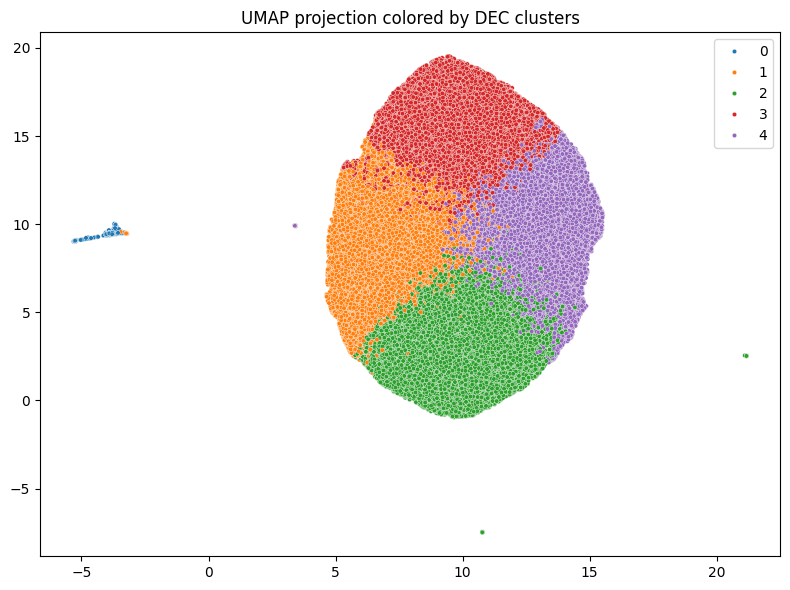

In [35]:
import seaborn as sns
import umap.umap_ as umap

reducer = umap.UMAP(n_components=2, random_state=42)
embedding_2d = reducer.fit_transform(embeddings)
print("UMAP done:", embedding_2d.shape)

plt.figure(figsize=(8,6))
sns.scatterplot(x=embedding_2d[:, 0], y=embedding_2d[:,1], hue=labels, palette="tab10", s=10, legend='full')
plt.title("UMAP projection colored by DEC clusters")
plt.tight_layout()
plt.savefig("umap_clusters.png", dpi=200)
plt.show()

# Cluster size and basic statistics

In [36]:
cluster_counts = pd.Series(labels).value_counts().sort_index()
print(cluster_counts)

cluster_counts.to_csv("cluster_counts.csv", header=['size'])

0      494
1    24952
2    29013
3    22558
4    22980
Name: count, dtype: int64


# Feature means per cluster (cluster profile)

In [40]:
df_num = df.select_dtypes(include=[np.number]).copy()
df_num['cluster'] = labels

cluster_means = df_num.groupby('cluster').mean()
cluster_stds = df_num.groupby('cluster').std()

# z-score
global_mean = df_num.drop(columns='cluster').mean()
global_std = df_num.drop(columns='cluster').std()
cluster_z = (cluster_means - global_mean) / (global_std + 1e-12)

In [41]:
topk = 8
profiles = {}
for c in cluster_z.index:
  z_scores = cluster_z.loc[c].sort_values(ascending=False)
  top_pos = z_scores.head(topk)
  top_neg = z_scores.tail(topk)
  profiles[c] = {'top_pos': top_pos, 'top_neg': top_neg}

# save full tables
cluster_means.to_csv("cluster_feature_mean.csv")
cluster_z.to_csv("cluster_feature_zscore.csv")

In [42]:
def readable_profile(cluster_id, top_pos, top_neg, count):
    lines = []
    lines.append(f"Cluster {cluster_id} (N={count}):")
    lines.append("  Characteristics (higher than average):")
    for k,v in top_pos.items():
        lines.append(f"    - {k}: z={v:.2f}")
    lines.append("  Characteristics (lower than average):")
    for k,v in top_neg.items():
        lines.append(f"    - {k}: z={v:.2f}")
    return "\n".join(lines)

profiles_text = []
for c in sorted(profiles.keys()):
    top_pos = profiles[c]['top_pos'].to_dict()
    top_neg = profiles[c]['top_neg'].to_dict()
    txt = readable_profile(c, top_pos, top_neg, int(cluster_counts.loc[c]))
    profiles_text.append(txt)

with open("cluster_profiles.txt", "w") as f:
    f.write("\n\n".join(profiles_text))

print("\n".join(profiles_text))


Cluster 0 (N=494):
  Characteristics (higher than average):
    - SocialEngagement: z=-4.23
    - EmotionalStability: z=-4.86
    - Interests: z=-5.10
    - Openness: z=-5.43
    - Responsibility: z=-5.86
    - Communication: z=-6.22
    - Lifestyle: z=-6.27
  Characteristics (lower than average):
    - SocialEngagement: z=-4.23
    - EmotionalStability: z=-4.86
    - Interests: z=-5.10
    - Openness: z=-5.43
    - Responsibility: z=-5.86
    - Communication: z=-6.22
    - Lifestyle: z=-6.27
Cluster 1 (N=24952):
  Characteristics (higher than average):
    - SocialEngagement: z=0.61
    - EmotionalStability: z=0.55
    - Interests: z=0.28
    - Lifestyle: z=0.12
    - Communication: z=-0.01
    - Responsibility: z=-0.23
    - Openness: z=-0.61
  Characteristics (lower than average):
    - SocialEngagement: z=0.61
    - EmotionalStability: z=0.55
    - Interests: z=0.28
    - Lifestyle: z=0.12
    - Communication: z=-0.01
    - Responsibility: z=-0.23
    - Openness: z=-0.61
Cluster 2 

# silhouette per cluster

In [43]:
X = df.select_dtypes(include=[np.number]).values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

from collections import defaultdict
sil_per_cluster = defaultdict(list)
sil_vals = silhouette_score(X_scaled, labels)  # global
# per-sample silhouette
from sklearn.metrics import silhouette_samples
samp_sil = silhouette_samples(X_scaled, labels)
for c in np.unique(labels):
    sil_per_cluster[c] = samp_sil[labels==c].mean()
print(sil_per_cluster)


defaultdict(<class 'list'>, {np.int64(0): np.float64(0.7668689847406379), np.int64(1): np.float64(0.08351605728709498), np.int64(2): np.float64(0.036724067810032304), np.int64(3): np.float64(0.10807751344949726), np.int64(4): np.float64(0.10179415507177929)})
